Website Traffic Data:
            Page_Views  Unique_Visitors  Bounce_Rate
Date                                                
2025-01-01  518.000000              242           34
2025-01-02  550.091574              214           33
2025-01-03  548.746396              250           31
2025-01-04  517.694187              237           35
2025-01-05  490.305813              216           35


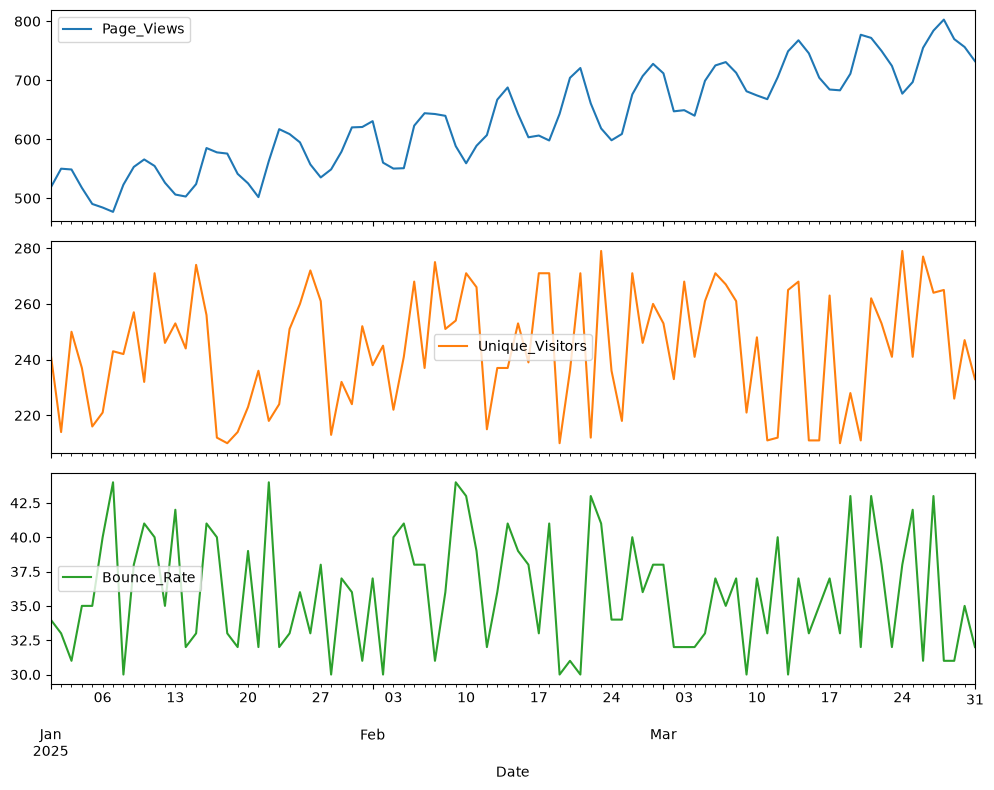

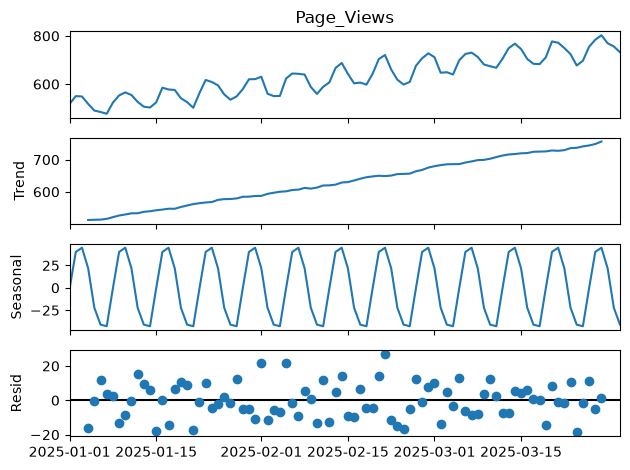

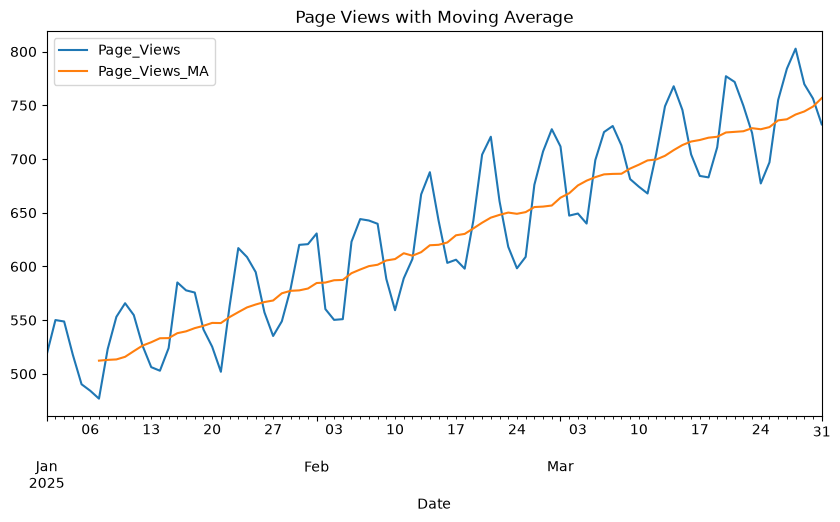

Detected Anomalies:
            Page_Views  Page_Views_Z
Date                                
2025-03-28  802.746396      2.031117


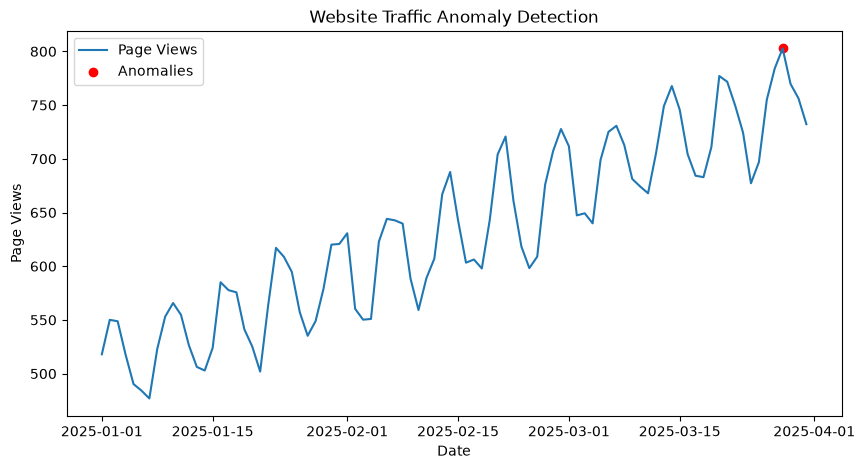

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

# Create sample website traffic data
np.random.seed(42)

dates = pd.date_range(start='2025-01-01', periods=90, freq='D')

data = pd.DataFrame({
    'Date': dates,
    'Page_Views': 500 + np.arange(90)*3 +
                  50*np.sin(2*np.pi*np.arange(90)/7) +
                  np.random.randint(-20, 20, 90),
    'Unique_Visitors': 200 + np.random.randint(10, 80, 90),
    'Bounce_Rate': 30 + np.random.randint(0, 15, 90)
})

data.set_index('Date', inplace=True)

# Handle missing values
data.interpolate(inplace=True)

# Display first five rows
print("Website Traffic Data:")
print(data.head())

# Plot website traffic
data[['Page_Views', 'Unique_Visitors', 'Bounce_Rate']].plot(
    subplots=True, figsize=(10, 8)
)
plt.tight_layout()
plt.show()

# Time series decomposition
decomposition = seasonal_decompose(
    data['Page_Views'], model='additive', period=7
)
decomposition.plot()
plt.show()

# Calculate moving average
data['Page_Views_MA'] = data['Page_Views'].rolling(window=7).mean()

data[['Page_Views', 'Page_Views_MA']].plot(figsize=(10, 5))
plt.title("Page Views with Moving Average")
plt.show()

# Detect anomalies using Z-score
data['Page_Views_Z'] = (
    data['Page_Views'] - data['Page_Views'].mean()
) / data['Page_Views'].std()

anomalies = data[data['Page_Views_Z'].abs() > 2]

print("Detected Anomalies:")
print(anomalies[['Page_Views', 'Page_Views_Z']])

# Visualize anomalies
plt.figure(figsize=(10, 5))
plt.plot(data.index, data['Page_Views'], label='Page Views')
plt.scatter(
    anomalies.index,
    anomalies['Page_Views'],
    color='red',
    label='Anomalies'
)
plt.title("Website Traffic Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("Page Views")
plt.legend()
plt.show()